## 0. Установка библиотек


In [ ]:
%pip install -q requests networkx scikit-learn nltk seaborn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
%matplotlib inline
import os
import re
from collections import Counter
from itertools import combinations

import matplotlib.pyplot as plt
import networkx as nx
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression

os.environ["NLTK_ALLOW_PROXIED_URLOPEN"] = "1"
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
sns.set_theme(style="whitegrid")


## 1. Выбор тематики

Категория **q-bio.PE (Populations and Evolution)**: модели эволюции и популяций, филогенетика, эпидемиология, популяционная генетика.


## 2. Сбор данных через OpenAlex API


In [ ]:
import requests
import pandas as pd

url = "https://api.openalex.org/works"
headers = {"User-Agent": "CourseDataPrep/1.0 (mailto:student@university.edu)"}

papers = []
for page in range(1, 5):
    params = {"search": "q-bio.PE",
              "per-page": 200,
              "page": page}

    response = requests.get(url, params=params, headers=headers)
    data = response.json()
    for item in data.get("results", []):
        inv = item.get("abstract_inverted_index") or {}
        words = [""] * (1 + max((i for pos in inv.values() for i in pos), default=-1))
        for w, pos in inv.items():
            for i in pos:
                words[i] = w
        authors = [a.get("author", {}).get("display_name") for a in item.get("authorships", [])]
        loc = item.get("primary_location") or {}
        papers.append({
            "title": item.get("title"),
            "year": item.get("publication_year"),
            "cited_by_count": item.get("cited_by_count", 0),
            "is_oa": item.get("open_access", {}).get("is_oa", False),
            "landing_page_url": loc.get("landing_page_url"),
            "authors": ", ".join(a for a in authors if a),
            "abstract": " ".join(words).strip(),
        })

df = pd.DataFrame(papers)
print(f"Загружено записей: {len(df)}")
df.head()


Загружено записей: 800


,title,year,cited_by_count,is_oa,landing_page_url,authors,abstract
0,Improving the Accuracy and Efficiency of Ident...,2013.0,758,True,https://doi.org/10.1534/genetics.113.150029,"Brian L. Browning, Sharon R. Browning",Segments of indentity-by-descent (IBD) detecte...
1,arXiv [q-bio.PE],2025.0,0,False,https://hdl.handle.net/21.11116/0000-0011-F4EF-D,"N. Mrnjavac, N. Hoffmann, M. Schlikker, M. Bur...",The origin of microbial cells required the eme...
2,Comparison of nasopharyngeal and oropharyngeal...,2020.0,276,True,https://doi.org/10.1016/j.ijid.2020.04.023,"Xiong Wang, Li Tan, Xu Wang, Weiyong Liu, Yanj...",BACKGROUND: Since the outbreak of coronavirus ...
3,"Immune life history, vaccination, and the dyna...",2020.0,334,True,https://doi.org/10.1126/science.abd7343,"Chadi M. Saad-Roy, Caroline E. Wagner, Rachel ...",The future trajectory of the coronavirus disea...
4,Information Theory Broadens the Spectrum of Mo...,2017.0,160,True,https://doi.org/10.1016/j.tree.2017.09.012,"William B. Sherwin, Anne Chao, Lou Jost, Peter...",


**Убираем записи до 2020 года**

In [ ]:
n_before = len(df)
df = df[df["year"] >= 2020].dropna(subset=["title"]).reset_index(drop=True)
print(f"Было {n_before}, осталось {len(df)} (year >= 2020)")
df.head()


Было 800, осталось 535 (year >= 2020)


,title,year,cited_by_count,is_oa,landing_page_url,authors,abstract
0,arXiv [q-bio.PE],2025.0,0,False,https://hdl.handle.net/21.11116/0000-0011-F4EF-D,"N. Mrnjavac, N. Hoffmann, M. Schlikker, M. Bur...",The origin of microbial cells required the eme...
1,Comparison of nasopharyngeal and oropharyngeal...,2020.0,276,True,https://doi.org/10.1016/j.ijid.2020.04.023,"Xiong Wang, Li Tan, Xu Wang, Weiyong Liu, Yanj...",BACKGROUND: Since the outbreak of coronavirus ...
2,"Immune life history, vaccination, and the dyna...",2020.0,334,True,https://doi.org/10.1126/science.abd7343,"Chadi M. Saad-Roy, Caroline E. Wagner, Rachel ...",The future trajectory of the coronavirus disea...
3,SARS-CoV-2 Infection and Cardiovascular Diseas...,2020.0,229,True,https://doi.org/10.1016/j.hlc.2020.05.101,"Bishnu P. Dhakal, Nancy K. Sweitzer, Julia H. ...",
4,Cyclic exit strategies to suppress COVID-19 an...,2020.0,111,True,https://doi.org/10.1101/2020.04.04.20053579,"Omer Karin, Yinon M. Bar‐On, Tomer Milo, Itay ...",Many countries have applied lockdown that help...


## 3. Разведочный анализ корпуса

Смотрим объём корпуса и частотную структуру слов.


In [ ]:
df["n_authors"] = df["authors"].fillna("").apply(lambda s: len([x for x in s.split(",") if x.strip()]))
df["title_len"] = df["title"].fillna("").str.split().str.len()
df["abs_len"] = df["abstract"].fillna("").str.split().str.len()

print("Публикаций:", len(df))
print("Годы:", int(df["year"].min()), "–", int(df["year"].max()))
print(df[["year", "cited_by_count", "n_authors", "title_len", "abs_len"]].describe().round(2))


Публикаций: 535
Годы: 2020 – 2026
          year  cited_by_count  n_authors  title_len  abs_len
count   535.00          535.00     535.00     535.00   535.00
mean   2022.03           10.03       4.17      12.72   199.78
std       2.10           27.17       4.54       5.33   113.84
min    2020.00            0.00       0.00       1.00     0.00
25%    2020.00            0.00       2.00       9.00   140.00
50%    2021.00            2.00       3.00      12.00   188.00
75%    2024.00            8.00       5.00      15.00   242.00
max    2026.00          334.00      45.00      33.00  1176.00


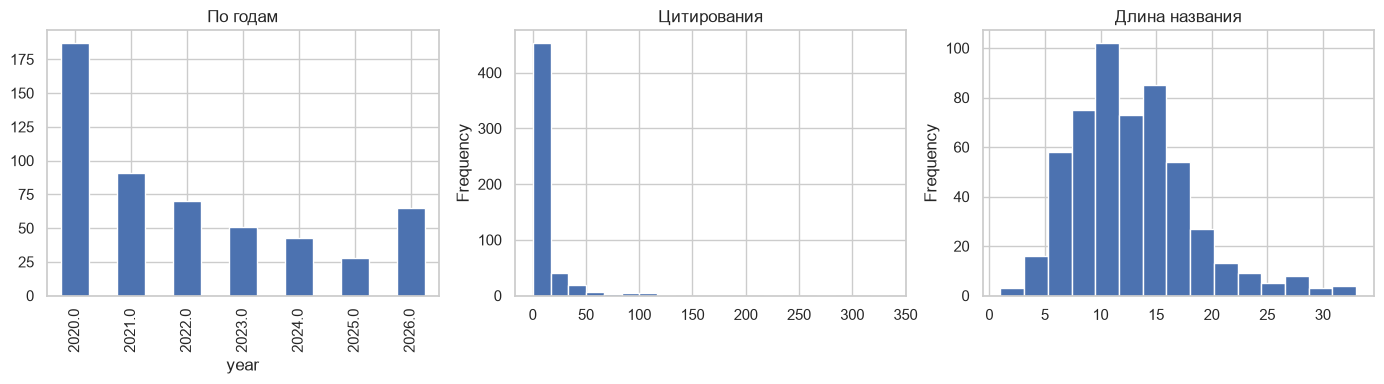

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
df["year"].value_counts().sort_index().plot.bar(ax=ax[0], title="По годам")
df["cited_by_count"].plot.hist(ax=ax[1], bins=20, title="Цитирования")
df["title_len"].plot.hist(ax=ax[2], bins=15, title="Длина названия")
plt.tight_layout()


s = 1.235, R² = 0.960


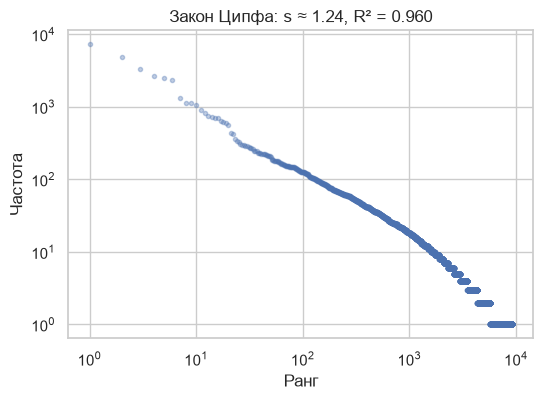

In [ ]:
tokens = []
for t in df["title"].fillna("") + " " + df["abstract"].fillna(""):
    tokens += re.findall(r"[a-z]+", t.lower())

freq = np.array(sorted(Counter(tokens).values(), reverse=True), dtype=float)
rank = np.arange(1, len(freq) + 1)
reg = LinearRegression().fit(np.log10(rank).reshape(-1, 1), np.log10(freq))
s = -float(reg.coef_[0])
r2 = float(reg.score(np.log10(rank).reshape(-1, 1), np.log10(freq)))

plt.figure(figsize=(6, 4))
plt.loglog(rank, freq, ".", alpha=0.35)
plt.xlabel("Ранг")
plt.ylabel("Частота")
plt.title(f"Закон Ципфа: s ≈ {s:.2f}, R² = {r2:.3f}")
print(f"s = {s:.3f}, R² = {r2:.3f}")


**Закон Хипса.** Размер словаря растёт с объёмом корпуса медленнее линейного. Ниже копим токены по текстам и смотрим, где лежит ли оценка.

β = 0.597, K = 8.91, R² = 0.996


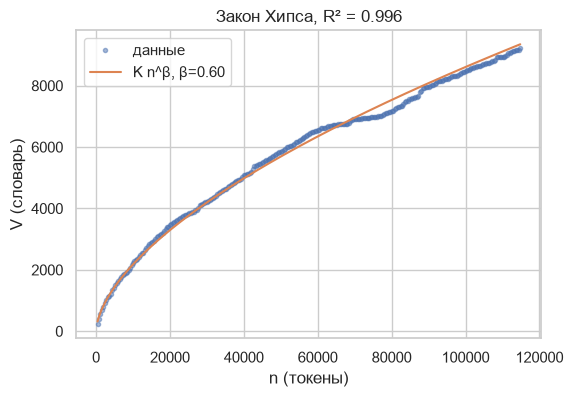

In [ ]:
docs = df["title"].fillna("") + " " + df["abstract"].fillna("")
seen, n_tok, V, N = set(), 0, [], []
for text in docs:
    for w in re.findall(r"[a-z]+", text.lower()):
        n_tok += 1
        seen.add(w)
        if n_tok % 400 == 0:
            N.append(n_tok)
            V.append(len(seen))

N, V = np.array(N, dtype=float), np.array(V, dtype=float)
reg = LinearRegression().fit(np.log(N).reshape(-1, 1), np.log(V))
beta = float(reg.coef_[0])
K = float(np.exp(reg.intercept_))
r2 = float(reg.score(np.log(N).reshape(-1, 1), np.log(V)))

plt.figure(figsize=(6, 4))
plt.plot(N, V, ".", alpha=0.5, label="данные")
plt.plot(N, K * N ** beta, label=f"K n^β, β={beta:.2f}")
plt.xlabel("n (токены)")
plt.ylabel("V (словарь)")
plt.title(f"Закон Хипса, R² = {r2:.3f}")
plt.legend()
print(f"β = {beta:.3f}, K = {K:.2f}, R² = {r2:.3f}")


**Что видно.** Закон Ципфа на лог–лог шкале близок к прямой (высокое \(R^2\)): несколько слов встречаются очень часто, большинство — редко. Закон Хипса: словарь растёт медленнее числа токенов. Дальше работаем с нормализованными ключевыми словами, а не с сырыми токенами.


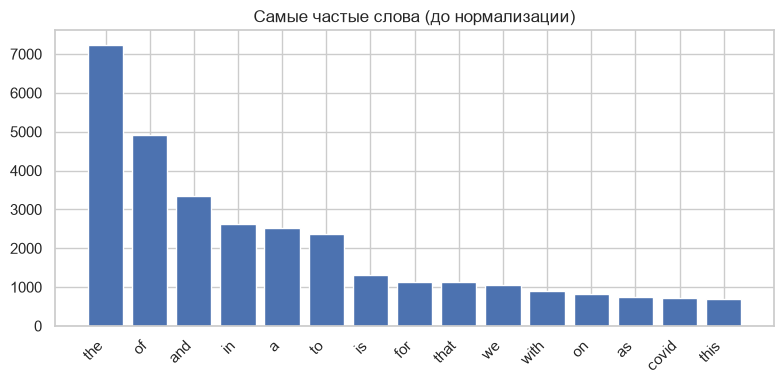

In [ ]:
top = Counter(tokens).most_common(15)
plt.figure(figsize=(8, 4))
plt.bar([w for w, _ in top], [c for _, c in top])
plt.xticks(rotation=45, ha="right")
plt.title("Самые частые слова (до нормализации)")
plt.tight_layout()


## 4. Ключевые слова публикаций

Название и аннотация склеиваются в один текст. Далее: нижний регистр, стоп-слова, лемматизация в единственное число (`patterns` → `pattern`), затем уни-/би-/триграммы через TF-IDF. Для каждой статьи берём несколько фраз с наибольшим TF-IDF.


In [ ]:
lemmatizer = WordNetLemmatizer()
STOP = set(stopwords.words("english")) | {"et", "al", "using", "based", "arxiv"}

def normalize(text):
    words = []
    for w in re.findall(r"[a-z]+", str(text).lower()):
        if len(w) <= 2 or w in STOP:
            continue
        words.append(lemmatizer.lemmatize(w))
    return " ".join(words)

df["text"] = (df["title"].fillna("") + " " + df["abstract"].fillna("")).map(normalize)
df["text"].head()


0    bio origin microbial cell required emergence m...
1    comparison nasopharyngeal oropharyngeal swab s...
2    immune life history vaccination dynamic sars c...
3    sars cov infection cardiovascular disease covi...
4    cyclic exit strategy suppress covid allow econ...
Name: text, dtype: str

In [ ]:
vec = TfidfVectorizer(ngram_range=(1, 3), min_df=3, max_features=3000)
X = vec.fit_transform(df["text"])
names = np.array(vec.get_feature_names_out())

def top_keywords(i, k=8):
    scores = X[i].toarray().ravel()
    idx = scores.argsort()[::-1][:k]
    return [names[j] for j in idx if scores[j] > 0]

df["keywords"] = [top_keywords(i) for i in range(len(df))]
df[["title", "keywords"]].head()


,title,keywords
0,arXiv [q-bio.PE],"[metabolism, metal, origin, reaction, enzyme, ..."
1,Comparison of nasopharyngeal and oropharyngeal...,"[swab, nasopharyngeal, specimen, positive, tes..."
2,"Immune life history, vaccination, and the dyna...","[immune, immune response, sars cov, cov, sars,..."
3,SARS-CoV-2 Infection and Cardiovascular Diseas...,"[sars cov infection, cov infection, disease co..."
4,Cyclic exit strategies to suppress COVID-19 an...,"[day, economic, lockdown, cyclic, suppress, re..."


In [ ]:
print("patterns ->", lemmatizer.lemmatize("patterns"))
print("algorithms ->", lemmatizer.lemmatize("algorithms"))

plural = sorted({
    w
    for kws in df["keywords"]
    for phrase in kws
    for w in phrase.split()
    if w != lemmatizer.lemmatize(w)
})
print("Множественные формы в ключевых словах:", plural or "нет")


patterns -> pattern
algorithms -> algorithm
Множественные формы в ключевых словах: нет


In [ ]:
n_gram = Counter(len(w.split()) for kws in df["keywords"] for w in kws)
print("униграмм / биграмм / триграмм:", n_gram[1], n_gram[2], n_gram[3])

freq = Counter(w for kws in df["keywords"] for w in kws)
print("Самые частые:")
for w, c in freq.most_common(15):
    print(f"  {c:3d}  {w}")


униграмм / биграмм / триграмм: 3650 547 23
Самые частые:
   44  model
   34  network
   33  corpus
   31  covid
   30  bio
   22  disease
   21  pandemic
   21  sir
   20  india
   19  epidemic
   19  state
   19  outbreak
   18  specie
   17  case
   17  number


## 5. Граф ключевых слов

Узел — ключевое слово. Ребро есть, если два слова встречаются вместе хотя бы в двух публикациях; вес — число таких совместных появлений.


In [ ]:
edges = Counter()
for kws in df["keywords"]:
    for a, b in combinations(sorted(set(kws)), 2):
        edges[(a, b)] += 1

G_kw = nx.Graph()
G_kw.add_weighted_edges_from((a, b, w) for (a, b), w in edges.items() if w >= 2)
print(f"Узлов: {G_kw.number_of_nodes()}, рёбер: {G_kw.number_of_edges()}")


Узлов: 569, рёбер: 1726


Text(0.5, 1.0, 'Граф совместной встречаемости ключевых слов')

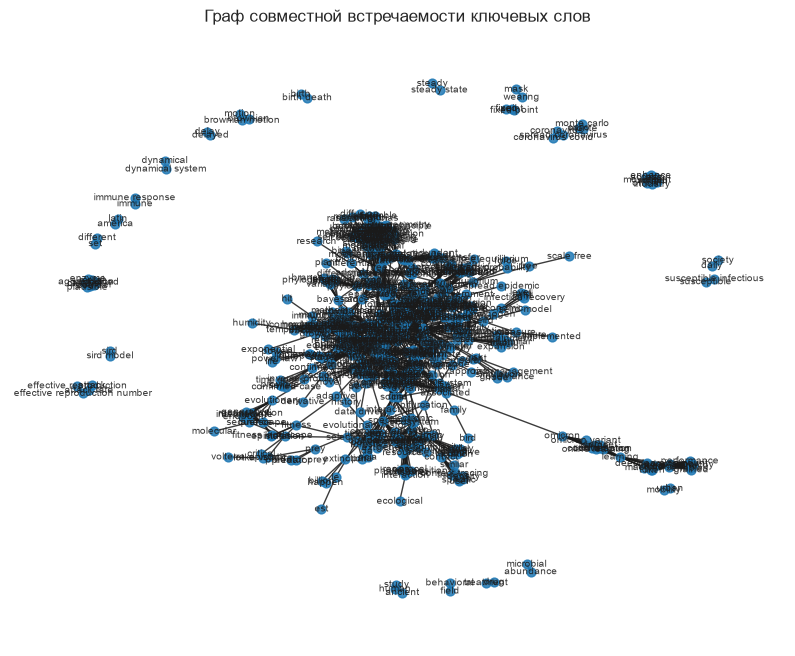

In [ ]:
pos_kw = nx.spring_layout(G_kw, seed=42)
plt.figure(figsize=(10, 8))
nx.draw_networkx(G_kw, pos_kw, node_size=40, font_size=7, alpha=0.85)
plt.axis("off")
plt.title("Граф совместной встречаемости ключевых слов")


## 6. Кластеры ключевых слов

Сообщества ищем алгоритмом **Louvain** (максимизация модулярности). Модулярность \(Q\) сравнивает долю рёбер внутри кластеров с той же долей в случайном графе с теми же степенями. Ориентиры: \(Q > 0.3\) — заметная кластерная структура, \(Q > 0.5\) — сильная.


In [ ]:
communities = nx.community.louvain_communities(G_kw, weight="weight", seed=42)
communities = sorted(communities, key=len, reverse=True)
Q = nx.community.modularity(G_kw, communities, weight="weight")
print(f"Кластеров: {len(communities)}, модулярность Q = {Q:.3f}")

cluster_of = {}
for cid, comm in enumerate(communities):
    for node in comm:
        cluster_of[node] = cid
    top = sorted(comm, key=G_kw.degree, reverse=True)[:12]
    print(f"{cid} ({len(comm)}): {', '.join(top)}")


Кластеров: 42, модулярность Q = 0.804
0 (79): model, sir, covid, disease, transmission, india, spread, sir model, optimal, solution, epidemiological model, adomian decomposition method
1 (60): corpus, bio, network, biological, regulatory, modularity, state, slow, representation, information, space, boolean
2 (45): number, evolution, reproduction number, reproduction, distribution, optimization, population, condition, method, first, general, distribution individual
3 (37): specie, ecosystem, phase, resource, genetic, interaction, patterned, coexistence, reciprocal, cycle, consumer, non
4 (36): individual, social, wave, distancing, uma, do, que, social distancing, da, every, rio, health
5 (33): pandemic, epidemic, equation, process, reported data, deterministic, function, infectivity, integral, exposed infectious, trait, total number
6 (33): infection, intervention, testing, cov, case, host, sars, intensity, dengue, sars cov, vector, fact
7 (32): mortality, death, logistic, japan, covid 

Text(0.5, 1.0, 'Кластеры Louvain')

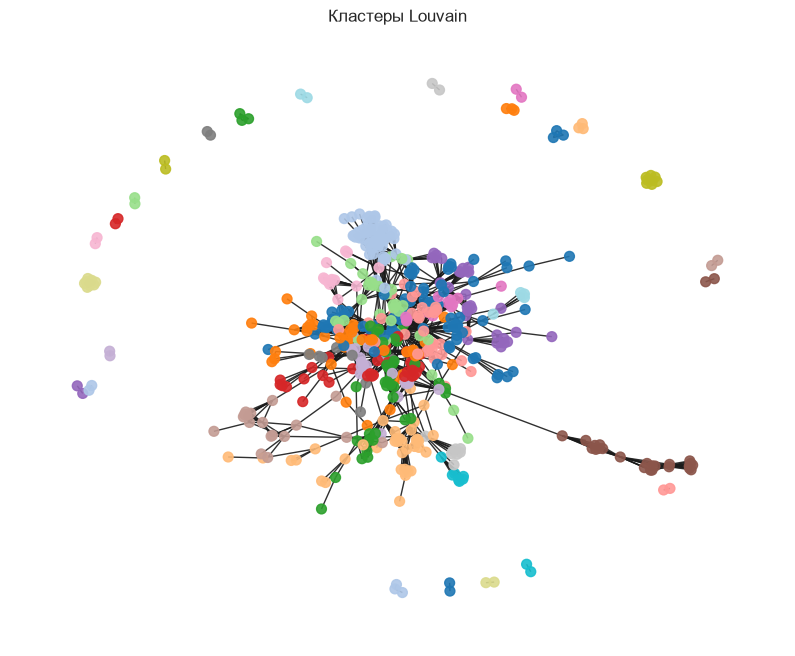

In [ ]:
colors = sns.color_palette("tab20", n_colors=max(len(communities), 3))
node_color = [colors[cluster_of[n]] for n in G_kw.nodes()]
plt.figure(figsize=(10, 8))
nx.draw_networkx(
    G_kw, pos_kw, node_color=node_color, node_size=50,
    with_labels=False, alpha=0.9,
)
plt.axis("off")
plt.title("Кластеры Louvain")


**Как читать кластеры.** Louvain максимизирует модулярность: чем выше \(Q\), тем сильнее слова внутри кластера связаны друг с другом, чем между кластерами. \(Q > 0.3\) — заметная структура. Кластеры обычно соответствуют темам (эпидемии, филогенетика, экология и т.д.).


## 7. Центральности ключевых слов

Считаем три меры:

- **Degree** — сколько разных терминов соседствует со словом
- **Betweenness** — как часто слово лежит на кратчайших путях (мост между темами)
- **Closeness** — насколько слово близко ко всем остальным


In [ ]:
degree = nx.degree_centrality(G_kw)
between = nx.betweenness_centrality(G_kw)
close = nx.closeness_centrality(G_kw)

def top(scores, k=8):
    return sorted(scores, key=scores.get, reverse=True)[:k]

print("degree:     ", top(degree))
print("betweenness:", top(between))
print("closeness:  ", top(close))


degree:      ['model', 'corpus', 'bio', 'network', 'sir', 'outbreak', 'pandemic', 'number']
betweenness: ['model', 'outbreak', 'covid', 'pandemic', 'variant', 'omicron', 'individual', 'network']
closeness:   ['model', 'covid', 'sir', 'pandemic', 'death', 'individual', 'mortality', 'epidemic']


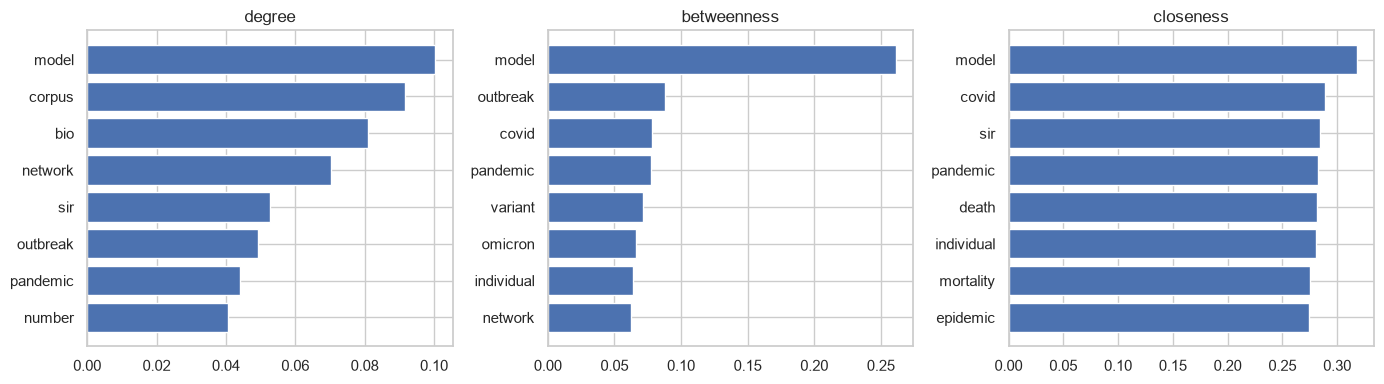

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, scores, title in zip(ax, [degree, between, close], ["degree", "betweenness", "closeness"]):
    nodes = top(scores)
    a.barh(nodes[::-1], [scores[n] for n in nodes][::-1])
    a.set_title(title)
plt.tight_layout()


**Интерпретация.** Degree — model, network, sir, outbreak.
Betweenness — слова-мосты между темами: outbreak, covid, pandemic, variant, omicron.
Closeness — насколько слово близко ко всем остальным: model, covid, sir, epidemi.

## 8. Граф публикаций

Узел — статья. Ребро есть, если у двух статей есть общее ключевое слово; вес равен числу общих ключевых слов. Ближайшие статьи — соседи с наибольшим весом.


In [ ]:
df["pid"] = df.index
paper_kws = {pid: set(kws) for pid, kws in zip(df["pid"], df["keywords"])}

G_pub = nx.Graph()
G_pub.add_nodes_from(df["pid"])
by_kw = {}
for pid, kws in paper_kws.items():
    for kw in kws:
        by_kw.setdefault(kw, []).append(pid)

for papers in by_kw.values():
    for a, b in combinations(papers, 2):
        if G_pub.has_edge(a, b):
            G_pub[a][b]["weight"] += 1
        else:
            G_pub.add_edge(a, b, weight=1)

print(f"Узлов: {G_pub.number_of_nodes()}, рёбер: {G_pub.number_of_edges()}")


Узлов: 535, рёбер: 9191


Text(0.5, 1.0, 'Фрагмент графа публикаций')

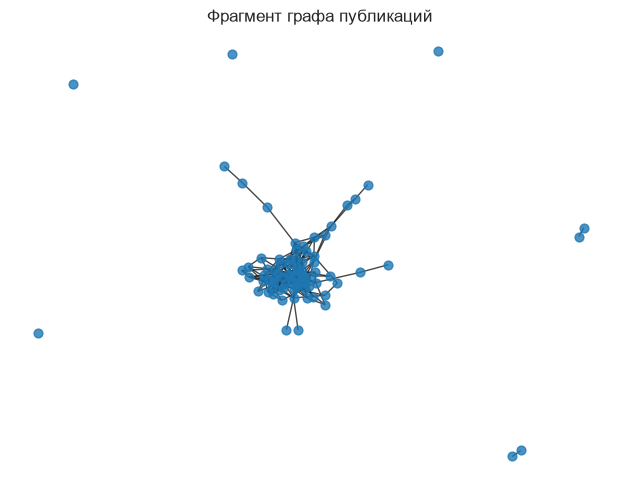

In [ ]:
# рисуем кусок графа, иначе сотни узлов нечитаемы
H = G_pub.subgraph(list(df["pid"])[:80])
pos = nx.spring_layout(H, seed=42)
plt.figure(figsize=(8, 6))
nx.draw_networkx(H, pos, node_size=40, with_labels=False, alpha=0.8)
plt.axis("off")
plt.title("Фрагмент графа публикаций")


In [ ]:
def similar_papers(pid, k=8):
    nbrs = sorted(G_pub[pid].items(), key=lambda x: -x[1]["weight"])[:k]
    return pd.DataFrame([
        {"pid": n, "shared": d["weight"], "title": df.loc[n, "title"]}
        for n, d in nbrs
    ])


### Поиск ближайших публикаций

Ребро в графе публикаций — общие ключевые слова, вес — сколько их. Ближайшие к статье = соседи с наибольшим весом.


In [ ]:
pid0 = int(df["cited_by_count"].idxmax())
print("Запрос:", df.loc[pid0, "title"])
print("Ключевые слова:", df.loc[pid0, "keywords"])
similar_papers(pid0)


Запрос: Immune life history, vaccination, and the dynamics of SARS-CoV-2 over the next 5 years
Ключевые слова: ['immune', 'immune response', 'sars cov', 'cov', 'sars', 'sars cov infection', 'cov infection', 'infection']


,pid,shared,title
0,3,6,SARS-CoV-2 Infection and Cardiovascular Diseas...
1,457,6,Placental expression of ACE2 and TMPRSS2 in ma...
2,82,3,Children and Fecal SARS-CoV-2 shedding: Just t...
3,165,3,The recency and geographical origins of the ba...
4,174,3,Variants of SARS-COV-2 and the Death Toll
5,193,3,HLA‐dependent variation in SARS‐CoV‐2 CD8 + T ...
6,271,3,Look before diving into pooling of SARS-CoV-2 ...
7,307,3,Statistical Challenges in Tracking the Evoluti...


### Поиск по текстовому запросу

Нормализуем запрос так же, как тексты статей, и считаем пересечение с ключевыми словами.


In [ ]:
def search_papers(query, k=8):
    q = set(normalize(query).split())
    scored = []
    for pid, kws in paper_kws.items():
        tokens = set(" ".join(kws).split())
        n = len(tokens & q)
        if n:
            scored.append((n, pid))
    scored.sort(reverse=True)
    return pd.DataFrame([
        {"pid": pid, "n_match": n, "title": df.loc[pid, "title"]}
        for n, pid in scored[:k]
    ])

search_papers("phylogenetic tree epidemic")


,pid,n_match,title
0,430,2,TreeProfiler: large-scale metadata profiling a...
1,429,2,Ranking top-k trees in tree-based phylogenetic...
2,398,2,Vector Encoding of Phylogenetic Trees by Order...
3,203,2,Strong phylogenetic signal despite high phylog...
4,514,1,On the comparison of incompatibility of split ...
5,508,1,Epidemic models with varying infectivity
6,477,1,Spatial spread of infection: transitions betwe...
7,460,1,On the Colijn-Plazzotta numbering scheme for u...


## 9. Тесты поиска

Проверяем, что у статьи есть соседи (отсортированные по весу) и что поиск по её ключевым словам находит её саму.


In [ ]:
pid0 = max(G_pub.nodes, key=G_pub.degree)

sim = similar_papers(pid0)
assert len(sim) > 0
assert list(sim["shared"]) == sorted(sim["shared"], reverse=True)

hits = search_papers(" ".join(df.loc[pid0, "keywords"]))
assert pid0 in set(hits["pid"])

print("Тесты прошли, статья", pid0)
sim.head()


Тесты прошли, статья 381


,pid,shared,title
0,138,2,An adapted ODE model to study the Dynamics of ...
1,10,2,Health system collapse 45 days after the detec...
2,384,2,The First Month Spread of COVID-19 in Madagascar
3,311,2,Hierarchical Modelling of COVID-19 Death Risk ...
4,361,2,Amplifiers of selection for the Moran process ...
